# Conjunto B — a mesma perda, uma decisão por dia

## Cinco decisões, antes de qualquer import

| Decisão | Definição |
|---|---|
| Unidade de análise | Um dia de chegada do City Hotel, somando o alvo da mesma população de A |
| Instante da decisão | Início de cada semana operacional de 7 dias |
| Janela de observação | Série desde 01/07/2015 até a origem menos 16 dias; embargo conservador de 15 dias |
| Janela de desempenho | Os 7 dias a partir da origem; passo entre origens de 7 dias |
| População elegível | Todos os dias do horizonte, contando as reservas de A elegíveis em cada chegada |

## Mesmos custos e quantidade recomendada

`Y` é a quantidade diária de cancelamentos tardios/no-shows entre reservas ativas
na véspera, de 1 a 14 noites e criadas antes da chegada. `q` é a quantidade de vagas
de **primeira noite** a oferecer adicionalmente. Cada vaga abaixo de `Y` custa
R$ 400 de oportunidade; cada vaga acima de `Y` custa R$ 1.200 de compensação.

`L(Y,q) = 400 × max(Y-q,0) + 1.200 × max(q-Y,0)`.

O quantil ótimo é `400 / (400 + 1.200) = 0,25`. Ele é complementar ao limiar de A
porque o erro caro, aqui, é superestimar as vagas liberadas. São os mesmos valores
hipotéticos e as mesmas limitações: procura substituta, vaga por reserva,
primeira noite, sem simular capacidade real ou receita observada.

O total futuro de reservas ativas não é usado como variável: ele ainda é
desconhecido na origem semanal. A previsão é marginal, baseada no passado.
Na operação, a elegibilidade de cada reserva será conhecida na sua véspera.
Isso torna B um planejamento antecipado, diferente da ação individual de A.

## Fontes e execução

- [Enunciado](../fontes/TRABALHO_extraclasse.pdf).
- Antonio, Almeida e Nunes (2019), [artigo original](https://doi.org/10.1016/j.dib.2018.11.126).
- [TidyTuesday, 11/02/2020](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11), espelho dos dados e dicionário.
- Cópias e metadados em `../fontes/` e `../dados/proveniencia.json`.
- Rotinas compartilhadas auditáveis: [metodo.py](../src/metodo.py). Não é necessário executar outro notebook antes deste.
- Dependências: `../requirements.txt`; instruções locais: `../COMO_EXECUTAR.md`.

O artigo é distribuído sob CC BY. O espelho atribui os dados aos autores;
não presumimos uma licença CC0 independente. Consulte a documentação preservada
para atribuição e condições. Houve uso de IA; a especificação e suas revisões estão
no `.md` ao lado deste notebook.

## 1. Fixar população e protocolo

Os modelos têm parâmetros simples predefinidos. A finalidade é comparar honestamente previsão e decisão, sem uma busca extensa que consuma o teste.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next(p for p in candidatas if (p / 'src/metodo.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
from metodo import *

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
bruto, dados, filtros = carregar_dados()
serie = construir_serie(dados)

origens = origens_b()
print('Modelos:',MODELOS_B)
print('Atraso:',ATRASO,'| horizonte:',HORIZONTE,'| passo: 7 dias')
print('SARIMA: (1,0,1)(1,0,0,7), com constante')

Modelos: ['Zero', 'Ingênuo sazonal', 'Média 28 dias', 'SARIMA']
Atraso: 15 | horizonte: 7 | passo: 7 dias
SARIMA: (1,0,1)(1,0,0,7), com constante


**Leitura:** zero é um adversário relevante em contagens raras. O ingênuo
sazonal repete recursivamente os últimos sete dias disponíveis, atravessando
o embargo. A média usa 28 dias. SARIMA tem sazonalidade semanal e parâmetros
fixos, ajustados de novo em cada origem; não usa AIC na série inteira nem
resultados do teste para escolher ordens. Convergência será registrada.

## 2. Calibrar a distribuição com erros fora da amostra

Um ponto não determina a decisão econômica. Estimamos uma distribuição aproximada usando erros de previsões reais em origens anteriores, preservando o atraso.

In [2]:
erros_cal = backtest_b(serie,origens['calibracao'])
erros_cal.to_csv(RAIZ/'resultados/previsoes_b_calibracao.csv',index=False)
display(erros_cal.groupby('modelo').agg(
    erros=('erro','size'),media_erro=('erro','mean'),
    desvio_erro=('erro','std'),convergencia=('convergiu','mean')))
assert (erros_cal.data.max()+pd.Timedelta(days=ATRASO)) <= origens['validacao'].min()

,erros,media_erro,desvio_erro,convergencia
modelo,,,,
Ingênuo sazonal,224,0.0223,5.0668,1.0000
Média 28 dias,224,0.0234,3.8551,1.0000
SARIMA,224,0.3984,3.8181,1.0000
Zero,224,2.0000,3.7357,1.0000


**Leitura:** os resíduos usados aqui vêm de previsões fora da amostra, não de
ajuste dentro do treino. Para cada previsão futura somamos o pool de erros do
mesmo modelo, truncamos em zero e arredondamos para contagem inteira. Os
quantis 10% e 90% formam uma banda nominal de 80%; o de 25% orienta a ação.

O pool é congelado antes da seleção. Ele mistura os sete horizontes operacionais
(16 a 22 passos desde a última observação), pressupõe estabilidade da distribuição
de erros e não representa trajetórias conjuntas. A cobertura é aproximada e
pode mudar com o regime. Não vamos somar quantis para alegar um quantil do total.

O ponto bruto usado nas métricas não precisa coincidir com a mediana da distribuição corrigida. Para o modelo Zero, a distribuição resultante é a distribuição histórica empírica do alvo nas origens de calibração; seu quantil de 25% recomenda zero. A comparação com a mediana usa essa mesma distribuição, não o ponto bruto.

## 3. Selecionar na validação

O critério principal é a perda da recomendação de 25%; o erro pontual funciona como desempate. Isso alinha a escolha à pergunta econômica.

In [3]:
bruto_val = backtest_b(serie,origens['validacao'])
val = distribuir_previsoes(bruto_val,erros_cal)
tabela_val,origem_val=metricas_b(val)
display(tabela_val)
vencedor_b = tabela_val.sort_values(['custo_q25','MAE']).index[0]
print('Modelo escolhido antes do teste:',vencedor_b)
print('Quantil econômico fixo:',QUANTIL)
assert (val.data.max()+pd.Timedelta(days=ATRASO)) <= INICIO_TESTE
val.to_csv(RAIZ/'resultados/previsoes_b_validacao.csv',index=False)
tabela_val.to_csv(RAIZ/'resultados/serie_metricas_validacao.csv')

,MAE,RMSE,MASE_treino,cobriu80,largura80,interval_score80,custo_q25,custo_mediana,custo_zero,desvio_MAE,desvio_RMSE,desvio_MASE,razao_MAE_sazonal_aula
modelo,,,,,,,,,,,,,
Média 28 dias,1.1023,1.3751,0.5940,0.9317,3.6087,4.6025,491.9255,626.0870,491.9255,0.3013,0.4697,0.1578,0.7584
SARIMA,1.1661,1.3879,0.6287,0.9565,4.0000,4.7453,511.8012,688.1988,491.9255,0.2818,0.4431,0.1478,0.8023
Zero,1.2298,1.7623,0.6620,0.9565,4.0000,4.7453,491.9255,688.1988,491.9255,0.5775,0.7117,0.3057,0.8462
Ingênuo sazonal,1.4534,1.8876,0.7829,0.8944,4.0807,5.5093,795.0311,"1,172.6708",491.9255,0.5163,0.5941,0.2731,1.0000


Modelo escolhido antes do teste: Média 28 dias
Quantil econômico fixo: 0.25


**Leitura:** MAE está em reservas por dia. RMSE pesa mais os erros grandes.
`MASE_treino` divide o MAE pela diferença sazonal absoluta média do treino de
cada origem; valores abaixo de 1 indicam erro menor que essa escala histórica.
Isso não implica automaticamente vencer o ingênuo no teste.

`razao_MAE_sazonal_aula` é a razão entre os MAEs no mesmo backtest, como no
material da disciplina: abaixo de 1 significa vencer o ingênuo sazonal nessa
avaliação; para o próprio ingênuo ela é exatamente 1. As duas métricas são
mostradas separadamente para não confundir definições.
`custo_q25` é a perda média diária em reais, não o custo por reserva.

## 4. Abrir o teste final

Modelo, custos e distribuição de erros já estão congelados. Avaliamos todas as referências para transparência, mas não trocamos o vencedor depois de olhar o teste.

In [4]:
bruto_teste = backtest_b(serie,origens['teste'])
teste = distribuir_previsoes(bruto_teste,erros_cal)
tabela_teste,origem_teste=metricas_b(teste)
display(tabela_teste)
print('Desvios de convergência:',int((~teste.drop_duplicates(['origem','modelo']).convergiu).sum()))
teste.to_csv(RAIZ/'resultados/previsoes_b_teste.csv',index=False)
tabela_teste.to_csv(RAIZ/'resultados/serie_metricas_teste.csv')
origem_teste.to_csv(RAIZ/'resultados/serie_metricas_por_origem.csv',index=False)
escolhido = teste.loc[teste.modelo.eq(vencedor_b)].copy()

,MAE,RMSE,MASE_treino,cobriu80,largura80,interval_score80,custo_q25,custo_mediana,custo_zero,desvio_MAE,desvio_RMSE,desvio_MASE,razao_MAE_sazonal_aula
modelo,,,,,,,,,,,,,
SARIMA,1.1283,1.4131,0.6283,0.9835,4.1044,4.9835,573.6264,740.6593,507.6923,0.4045,1.0269,0.2237,0.7256
Média 28 dias,1.2117,1.5539,0.6734,0.9176,3.5000,5.1484,571.4286,738.4615,507.6923,0.5363,1.0779,0.2928,0.7793
Zero,1.2692,1.8075,0.7079,0.9780,4.0000,4.9341,507.6923,661.5385,507.6923,0.6367,1.1424,0.3552,0.8163
Ingênuo sazonal,1.5549,2.3995,0.8652,0.9560,4.1429,7.8242,"1,017.5824","1,320.8791",507.6923,1.1913,2.7538,0.6627,1.0000


Desvios de convergência: 0


**Leitura:** média e desvio entre semanas descrevem estabilidade, sem garantir
independência dos erros. As janelas de treino se sobrepõem, embora os alvos
semanais não. A banda é um intervalo de **previsão de uma contagem futura**,
não um intervalo de confiança da média. Como as contagens são discretas e os
intervalos inclusivos, cobertura acima de 80% pode ocorrer; uma banda enorme
também cobre muito. Por isso mostramos largura e escore de intervalo, que
penaliza simultaneamente amplitude e falhas de cobertura.

## 5. Erro por horizonte e banda de 80%

Além da média, queremos saber quando a previsão e a recomendação falham. O horizonte começa na origem operacional, após atravessar o embargo.

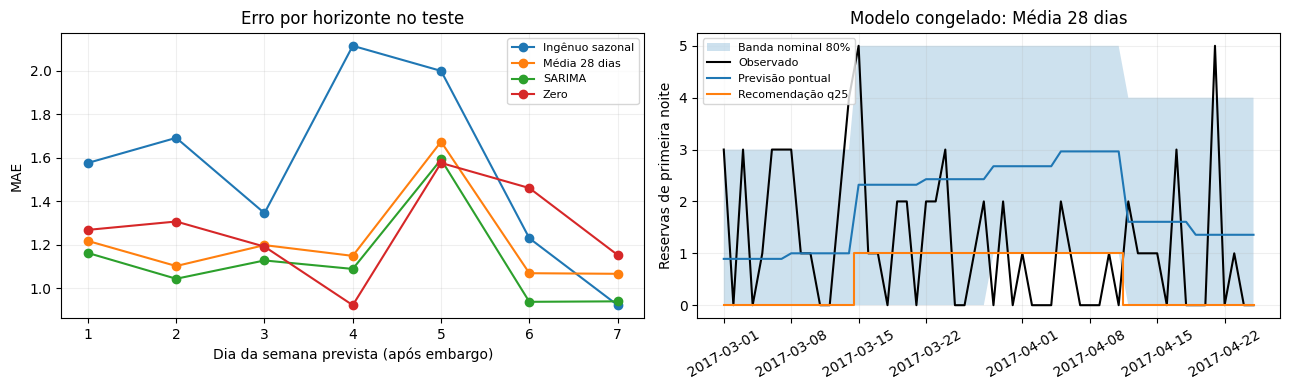

,origem,data,real,ponto,inferior80,superior80,q25,custo_q25
14,2017-03-01,2017-03-01,3,0.8929,0,3,0,"1,200.0000"
15,2017-03-01,2017-03-02,0,0.8929,0,3,0,0.0000
16,2017-03-01,2017-03-03,3,0.8929,0,3,0,"1,200.0000"
17,2017-03-01,2017-03-04,0,0.8929,0,3,0,0.0000
18,2017-03-01,2017-03-05,1,0.8929,0,3,0,400.0000
19,2017-03-01,2017-03-06,3,0.8929,0,3,0,"1,200.0000"
20,2017-03-01,2017-03-07,3,0.8929,0,3,0,"1,200.0000"
42,2017-03-08,2017-03-08,3,1.0000,0,3,0,"1,200.0000"
43,2017-03-08,2017-03-09,1,1.0000,0,3,0,400.0000
44,2017-03-08,2017-03-10,1,1.0000,0,3,0,400.0000


In [5]:
fig,eixos=plt.subplots(1,2,figsize=(13,4))
for nome,g in teste.groupby('modelo'):
    erros=g.assign(absoluto=(g.real-g.ponto).abs()).groupby('horizonte').absoluto.mean()
    eixos[0].plot(erros.index,erros.values,marker='o',label=nome)
eixos[0].set(xlabel='Dia da semana prevista (após embargo)',ylabel='MAE',title='Erro por horizonte no teste')
eixos[0].legend(fontsize=8)
janela=escolhido.loc[escolhido.data.between('2017-03-01','2017-04-25')]
eixos[1].fill_between(janela.data,janela.inferior80,janela.superior80,alpha=0.22,label='Banda nominal 80%')
eixos[1].plot(janela.data,janela.real,color='black',label='Observado')
eixos[1].plot(janela.data,janela.ponto,label='Previsão pontual')
eixos[1].step(janela.data,janela.q25,where='mid',label='Recomendação q25')
eixos[1].set(title='Modelo congelado: '+vencedor_b,ylabel='Reservas de primeira noite')
eixos[1].legend(fontsize=8);eixos[1].tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()
display(escolhido[['origem','data','real','ponto','inferior80','superior80','q25','custo_q25']].head(14))

**Leitura:** a recomendação inteira de 25% tende a ficar abaixo da previsão
central porque revender uma vaga que não será liberada custa três vezes mais.
A tabela permite reconstruir o custo de cada dia. Um zero recomendado é uma
decisão válida; não é um erro de arredondamento. Não limitamos `q` pela exposição
futura, pois ela é desconhecida na origem. Produção precisaria combinar esse
planejamento com inventário e reservas realmente ativas.

## 6. Estabilidade, decisão e comparação integrada

Comparar a recomendação econômica com a mediana da mesma distribuição isola o efeito da assimetria. Comparamos também com nunca revender.

In [6]:
mensal=escolhido.groupby(escolhido.data.dt.to_period('M')).agg(
    dias=('data','size'),real=('real','sum'),recomendacoes=('q25','sum'),
    custo_q25=('custo_q25','sum'),custo_mediana=('custo_mediana','sum'),
    custo_zero=('custo_zero','sum'),cobertura=('cobriu80','mean'))
display(mensal)
resumo_b={'vencedor':vencedor_b,'quantil':QUANTIL,'n_dias_teste':len(escolhido),
    'n_origens_teste':int(escolhido.origem.nunique()),
    'custo_q25':float(escolhido.custo_q25.sum()),
    'custo_mediana':float(escolhido.custo_mediana.sum()),
    'custo_zero':float(escolhido.custo_zero.sum()),
    'economia_vs_zero':float(escolhido.custo_zero.sum()-escolhido.custo_q25.sum()),
    'cobertura80':float(escolhido.cobriu80.mean()),
    'largura80':float(escolhido.largura80.mean()),
    'real_total':int(escolhido.real.sum()),'recomendacoes_total':int(escolhido.q25.sum()),
    'validacao':tabela_val.reset_index().to_dict('records'),
    'teste':tabela_teste.reset_index().to_dict('records'),
    'falhas_convergencia':int((~teste.drop_duplicates(['origem','modelo']).convergiu).sum())}
salvar_json('resumo_b.json',resumo_b)
mensal.to_csv(RAIZ/'resultados/serie_mensal.csv')
print('Perda da recomendação econômica:',moeda(resumo_b['custo_q25']))
print('Perda usando mediana:',moeda(resumo_b['custo_mediana']))
print('Perda sem revendas:',moeda(resumo_b['custo_zero']))
if (RAIZ/'resultados/resumo_a.json').exists():
    resumo_a=json.loads((RAIZ/'resultados/resumo_a.json').read_text())
    assert resumo_a['positivos_teste']==resumo_b['real_total']
    assert resumo_a['baseline_teste']==resumo_b['custo_zero']
    print('Coerência entre A e B verificada: mesmo alvo total e mesma perda sem ação.')

,dias,real,recomendacoes,custo_q25,custo_mediana,custo_zero,cobertura
data,,,,,,,
2017-03,31,47,17,"21,600.0000","29,200.0000","18,800.0000",0.9032
2017-04,30,26,11,"17,200.0000","37,200.0000","10,400.0000",0.7000
2017-05,31,62,0,"24,800.0000","20,800.0000","24,800.0000",0.9355
2017-06,30,36,7,"16,400.0000","16,800.0000","14,400.0000",1.0000
2017-07,31,29,0,"11,600.0000","18,400.0000","11,600.0000",1.0000
2017-08,29,31,0,"12,400.0000","12,000.0000","12,400.0000",0.9655


Perda da recomendação econômica: R$ 104.000,00
Perda usando mediana: R$ 134.400,00
Perda sem revendas: R$ 92.400,00
Coerência entre A e B verificada: mesmo alvo total e mesma perda sem ação.


**Leitura:** A decide individualmente quando o snapshot da véspera existe;
B planeja uma quantidade semanalmente com dados mais antigos. As ações não
são equivalentes e suas economias não devem ser somadas. A consistência exigida
é a do alvo, população e custos. A soma de recomendações é um volume de decisões
diárias, não o quantil de uma distribuição do total. Não simulamos esse total.

Sob mudança de regime, a distribuição de erros pode envelhecer. Não recalibramos
com o teste para melhorar a cobertura retrospectivamente. Se o baseline vencer,
a conclusão correta é preservá-lo e registrar a limitação, não buscar outro
modelo até obter um resultado favorável.

<!-- RESULTADOS_B2 -->

## Recomendação final: previsão melhor não bastou

**Média 28 dias** foi selecionada antes do teste: empatou com a política zero
no custo da validação (**R$ 491,93 por dia**) e
venceu o desempate por MAE. A regra de desempate estava definida antes de abrir
o teste e foi preservada, mesmo com o resultado desfavorável posterior.

Nas **26 origens e 182 dias de teste**, o MAE
foi **1,212 reservas/dia**, contra
1,555 do ingênuo sazonal: redução descritiva
de **22,1%**. O MASE com escala no treino foi
0,673; a razão de MAEs usada na aula foi
0,779. O desvio semanal do MAE
foi 0,536; uma média menor não demonstra,
sozinha, superioridade estatística. SARIMA teve MAE menor no teste, mas não foi
escolhido na validação e não é promovido retrospectivamente.

A banda nominal de 80% cobriu **91,8%** dos dias,
com largura média de **3,50 reservas**. Isso é sobrecobertura
global, não calibração perfeita: em abril, a cobertura foi apenas 70,0%.
A discretização, o pool fixo de erros e a mudança de regime limitam a leitura.
Nenhum ajuste SARIMA falhou na convergência das origens executadas.

| Política no teste | Perda incremental simulada |
|---|---:|
| Nunca revender | R$ 92.400,00 |
| Quantil de custo de 25%, modelo congelado | R$ 104.000,00 |
| Mediana da mesma distribuição | R$ 134.400,00 |

O quantil de custo economizou **R$ 30.400,00 frente à mediana**, mas
**perdeu R$ 11.600,00 frente a nunca revender**. As
35 vagas recomendadas produziram 16 unidades
excedentes e 212 oportunidades não aproveitadas no cenário simulado.
O resultado é consistente com os mesmos 231 positivos do teste de A;
a perda sem ação é idêntica nos dois conjuntos.

**Para a gestão:** não adote a política experimental de revenda com base neste
teste. Preserve o benchmark sem revendas e investigue a estabilidade da distribuição
antes de outro piloto. O modelo selecionado continua registrado como média móvel;
rejeitar sua implantação não é trocar o vencedor depois de olhar o teste.

## O mesmo problema, dois instrumentos

A usa uma probabilidade por reserva na chegada; B planeja uma quantidade por dia
no início da semana, com histórico maduro mais antigo. O limiar 0,75 e o quantil
0,25 derivam dos mesmos R$ 1.200 contra R$ 400. A não demonstrou ganho econômico;
B mostrou que reduzir erro pontual e usar um quantil teoricamente correto não
compensa uma distribuição de previsão inadequada ao novo período.

Não some economias de A e B: são políticas alternativas sob informações distintas.
Não some quantis diários para afirmar um quantil do total. Os resultados se
restringem à primeira noite da população elegível e às hipóteses de custos,
procura de reposição e reconstrução histórica já declaradas.

## Referências técnicas

- [Hyndman e Athanasopoulos — avaliação de previsões, escalas e intervalos](https://otexts.com/fpp3/toolbox.html).
- [statsmodels — SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html).

As referências sustentam o método; os números desta entrega são calculados
da cópia local dos dados, não copiados de exemplos externos.